In [6]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()  
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [8]:
from typing import Annotated
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict

from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph , START, END
from langgraph.checkpoint.memory import MemorySaver

from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import interrupt


class State(TypedDict):
    messages:Annotated[list,add_messages]

graph_builder = StateGraph(State)

@tool
def human_assistance(query: str) -> str:
    """Request human assistance for a specific query."""
    human_response = interrupt({"query": query})
    return human_response["response"]


search_tool = TavilySearch(max_results=2)
tools = [search_tool, human_assistance]

# Use bind_tools, not bundle_tools
llm_with_tools = llm.bind_tools(tools)



def chatbot(state: State) -> State:
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


graph_builder = StateGraph(State)

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_node("tools", ToolNode(tools))

graph_builder.add_edge(START, "chatbot")

# The condition sends tool calls to "tools", otherwise it ends
graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)

graph_builder.add_edge("tools", "chatbot")

app = graph_builder.compile(
    checkpointer=MemorySaver()
)

In [10]:
memory = MemorySaver()
graph= graph_builder.compile(checkpointer=memory)

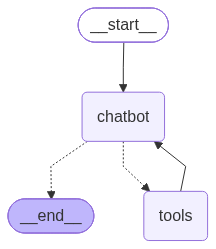

In [13]:
from IPython.display import display, Image
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
user_input = "Hello, can you tell me about the latest advancements in AI?"
config = {"configurable": {"thread_id": "1"}}

events = graph.stream({"messages": user_input}, config, stream_mode="values")

for event in events:
    if "messages" in event:
       event["messages"][-1].pretty_print()  # Print the last message in the list, which is the bot's response

================================ Human Message =================================

Hello, can you tell me about the latest advancements in AI?
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_265745)
 Call ID: call_265745
  Args:
    query: major AI breakthroughs and trends 2026
    search_depth: advanced
================================= Tool Message =================================
Name: tavily_search

{"query": "major AI breakthroughs and trends 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://news.microsoft.com/source/features/ai/whats-next-in-ai-7-trends-to-watch-in-2026", "title": "What’s next in AI: 7 trends to watch in 2026", "content": "After several years of experimentation, 2026 is shaping up to be the year AI evolves from instrument to partner, transforming how we work, create and solve problems. Across industries, AI is moving beyond answering questions to co

In [20]:

from langgraph.types import Command

human_feedback = ("The response was informative, but could you provide more details on the ethical implications of these advancements?")

human_command =Command(resume={"data": human_feedback})

events = graph.stream(human_command, config, stream_mode="values")

for event in events:
    if "messages" in event:
       event["messages"][-1].pretty_print()  # Print the last message in the list, which is the bot's response

================================== Ai Message ==================================

[{'type': 'text', 'text': 'The artificial intelligence landscape has been shifting rapidly, moving away from simple question-answering chatbots toward **active collaboration, autonomous execution, and deep scientific integration**. \n\nThe most prominent advancements and trends in AI span several key areas:\n\n### 1. From Passive Assistants to "Agentic" Workflows\nThe biggest shift is the maturation of **AI agents**. Instead of just responding to a prompt, modern AI systems can plan, use software tools, connect data across departments, and autonomously execute complex multi-step workflows. \n* **Team & Workflow Orchestration:** AI is increasingly integrated into enterprise platforms to manage entire projects from idea to completion, anticipating user needs rather than just following literal instructions.\n* **Specialized Hardware:** The industry is even exploring new classes of chips and architectures spe